# The MCCD guide: how a death certificate works, and how this pipeline writes one

This notebook teaches the domain and the code together. You will follow one record, S01, from a
clinical narrative to a coded certificate, and run each function of the pipeline on it yourself.
Where a function behaves differently in different situations, you will see those situations one at
a time, with the outcome stated before the cell runs, so you can check your understanding against
the output.

The order is the order the domain has:

1. What a death certificate is, and why the order of Part I matters.
2. The underlying cause of death, and how the WHO's DORIS selects it.
3. Why free text fails: ill-defined causes and invented evidence.
4. Our stages one by one, each run on S01 and read aloud.
5. The routes, and what a reviewer does with them.
6. How we measure whether any of this works.

Take your time with sections 1 to 3 even if you came for the code. Every rule in the validator and
every reason code in the router exists because of something in those sections.

The cells call the live model and the WHO container, so start the stack with `make up` first.


In [1]:
import copy, json
from _helpers import *
from automccd_lite.config import settings
from automccd_lite.code import FileCodeCache, IcdClient, IcdCertificate, code_draft, cache_key
from automccd_lite.draft import asker, make_client, draft_certificate
from automccd_lite.models import Draft, Record, Route
from automccd_lite.prompt import build_prompt, system_prompt, render
from automccd_lite.validate import validate_draft, validate, validate_schema
from automccd_lite.revise import revise_draft, revise_terms, low_score_terms, scoped_to_terms
from automccd_lite.route import route_draft
from automccd_lite.certificate import generate_certificate, as_response
from automccd_lite.pipeline import Deps, certify_record
from automccd_lite.eval import gold_to_cert, chain_to_cert, load_gold, scenarios, demographics, age_from_iso

cfg = settings()
icd = IcdClient(cfg.env.icd_api_url, cfg.code.icd_release, cfg.code.linearization, cfg.code.timeout_s, cfg.code.max_retries)
cache = FileCodeCache(icd)
ask = asker(make_client(cfg))
deps = Deps(ask=ask, icd=icd, cache=cache)
record = load_record("S01")
assert icd.available(), "the icd-api container is not up; run `make up`"
print("model:", cfg.draft.model, "| ICD release:", cfg.code.icd_release, "| record:", record.record_id)

model: gpt-5-nano-2025-08-07 | ICD release: 2026-01 | record: S01


## 1. What a death certificate is

When someone dies, a doctor fills in a Medical Certificate of Cause of Death, the MCCD. The WHO
publishes an international form so that every country records deaths the same way, and the
statistics built from those forms (which diseases kill people, at what ages, where) rest on one
field above all others: the **underlying cause of death**. That is the disease or injury that
started the chain of events leading to death. Not the last event, the first.

The form captures that chain in **Part I**, which you read from the bottom up:

- **Line 1a** is the immediate cause, what the person actually died of.
- **Line 1b** is what caused 1a. **Line 1c** is what caused 1b, and so on, down to 1d.
- The lowest line you use is the originating condition, and that is the underlying cause.

Each line carries an **interval**: how long before death that condition began. Because each line
causes the one above it, intervals cannot shrink as you go down. A condition that started two days
ago cannot have caused one that started five years ago.

**Part II** holds other significant conditions that contributed to the death but were not part of
that causal chain: a diabetes that weakened the patient, say, but did not start the sequence.

Below is the certificate the client's teaching material gives as the answer for S01. Read the
narrative again (section 2 of the how-to guide shows it), then read this form from the bottom up:
meningitis, which became sepsis, which became septic shock, which killed the patient. Diabetes and
the transplant contributed but sit in Part II.


In [2]:
gold = load_gold("S01")
gold_cert = gold_to_cert(gold)
render_mccd(gold_cert, title="S01: the client's answer (gold certificate)")

### Why the order matters

Suppose a doctor writes the same three conditions in the opposite order: meningitis on 1a, septic
shock on the bottom line. Every word is still true, and the patient still had all three. But the
certificate now claims that shock caused the meningitis, and the statistics would count this as a
death from shock, a symptom, not from a bacterial infection, a preventable cause. Public health
programmes are planned on those counts. The order is the medicine.

You will see that difference measured in the next section.


## 2. The underlying cause, and how DORIS selects it

A certificate is free text. Statistics need codes. The WHO's **ICD-11** is the classification that
gives every disease a code (`1D01.0` is Staphylococcus aureus meningitis), and the WHO ships a
container, the **ICD-API**, with three tools we use:

- **autocode** turns a written diagnosis into the closest ICD-11 code, with a match score between
  0 and 1 that says how sure it is.
- **DORIS** reads the coded certificate and selects the underlying cause. Usually that is the lowest
  line, but DORIS applies the WHO's selection rules on top: some conditions cannot be an
  underlying cause and DORIS moves past them, some sequences are implausible and DORIS rejects
  them. It returns the code it chose and a report of the rules it applied.
- **CoDEdit** runs quality checks and returns issue ids. `FER-CE-931` is the one we care most about:
  the underlying cause is **ill-defined**, meaning the certificate tells the statistician nothing.

The function `code_draft` runs all three on a certificate. Here it codes the gold certificate.
What to look for: each Part I term gets a code and a score of 1.0, because the gold uses standard
names; DORIS's `ucod_stem_code` is the meningitis line's code, the lowest line; and the DORIS report
walks you through the rule it applied. One surprise to expect: CoDEdit raises a `BER-CE-1` remark.
"Renal transplant" in Part II autocodes to an injury-chapter code that wants an external cause, and
DORIS invents a default one. That is a quirk of the WHO tooling on this record, and it is also why
S01 almost never routes `auto` through this pipeline: a CoDEdit remark is a reason for review.


In [3]:
coded_gold = code_draft(gold_cert, cache, icd, record.demographics)
print("codes per Part I line :", coded_gold.codes["part1"])
print("autocode match scores :", coded_gold.code_scores)
print("DORIS underlying cause:", coded_gold.doris["ucod_stem_code"], "(full:", coded_gold.doris["ucod_code"], ")")
print("CoDEdit issues        :", coded_gold.codedit["issue_ids"] or "none")
print()
print("DORIS report:")
print(coded_gold.doris["report"])

codes per Part I line : ['1G41', '1B5Z', '1B54']
autocode match scores : [1.0, 1.0, 1.0]
DORIS underlying cause: 1B54 (full: 1B54/1G41 )
CoDEdit issues        : ['BER-CE-1']

DORIS report:
The following conditions - NE84 - were reported without an external cause, a default external cause code - NE84>NE84/PB6Z - has been assigned. Manual check of the UCOD is needed, compliant with local and national rules and regulations. 
The external cause (PB6Z) has been placed at the beginning of the cluster, followed by the injury (NE84).
SP3: 1B54 is the first condition on the lowest used line causing all entries above, and is selected as the tentative starting point (TSP).
1G41 are manifestations of the selected underlying cause of death 1B54 and it is added as a postcoordination - 1B54>1B54/1G41.


Full report:
The following conditions - NE84 - were reported without an external cause, a default external cause code - NE84>NE84/PB6Z - has been assigned. Manual check of the UCOD is needed, complian

### The same conditions, reversed

Now the experiment from section 1. The cell reverses Part I so that septic shock sits on the bottom
line. Expected outcome: the codes per line are the same codes in the opposite order. DORIS's
selection rules know that meningitis causes sepsis and sepsis causes shock, so this time it still
finds its way back to the meningitis; but read the warning and the CoDEdit list: a new `BER-CE-22`
says the sequence as written is not acceptable. The WHO rules rescued this certificate because the
three conditions are medically linked. Write two unrelated conditions in the wrong order and no rule
will rescue you: the wrong one becomes the underlying cause, silently.


In [4]:
reversed_cert = copy.deepcopy(gold_cert)
reversed_cert["part1"] = list(reversed(reversed_cert["part1"]))
coded_rev = code_draft(reversed_cert, cache, icd, record.demographics)
print("codes per Part I line :", coded_rev.codes["part1"])
print("DORIS underlying cause:", coded_rev.doris["ucod_stem_code"], " (was", coded_gold.doris["ucod_stem_code"], "in the right order)")
print("DORIS warning         :", coded_rev.doris.get("warning"))
print("CoDEdit issues        :", coded_rev.codedit["issue_ids"] or "none")

codes per Part I line : ['1B54', '1B5Z', '1G41']
DORIS underlying cause: 1B54  (was 1B54 in the right order)
DORIS warning         : The following conditions - NE84 - were reported without an external cause, a default external cause code - NE84>NE84/PB6Z - has been assigned. Manual check of the UCOD is needed, compliant with local and national rules and regulations.
External cause or injury is mentioned - PB6Z/NE84 - but is not the tentative underlying cause - 1B54.
The postcoordinations - 1G41 - were selected from conditions that are potential manifestations of the tentative underlying cause - 1B54, manual check of their validity is needed.

CoDEdit issues        : ['BER-CE-1', 'BER-CE-22']


## 3. Why free text fails

Two things go wrong when a certificate is written carelessly, by a tired doctor or by a language
model, and both are invisible to a reader who does not know the rules.

**Ill-defined causes.** "Cardiac arrest", "respiratory failure", "multi-organ failure" are modes of
dying: every death ends in the heart stopping. A certificate whose underlying cause is one of these
says nothing about why the person died. The WHO calls these ill-defined, CoDEdit flags them with
`FER-CE-931`, and our validator rule V2 refuses them on any Part I line before coding even starts.

Expected outcome below: a certificate consisting of "Cardiac arrest" alone codes fine (autocode
finds a code for it), DORIS selects it, and CoDEdit's ill-defined flag is **true**. Coding does not
catch the problem; only the quality check does, which is why we run CoDEdit a second time on the
selected underlying cause alone.


In [5]:
arrest = chain_to_cert(["Cardiac arrest"])
coded_arrest = code_draft(arrest, cache, icd, record.demographics)
print("code                  :", coded_arrest.codes["part1"], "score", coded_arrest.code_scores)
print("DORIS underlying cause:", coded_arrest.doris["ucod_stem_code"])
print("CoDEdit on the UCOD   :", coded_arrest.codedit_ucod["issue_ids"], "ill_defined =", coded_arrest.codedit_ucod["ill_defined"])

code                  : ['MC82.Z'] score [1.0]
DORIS underlying cause: MC82.Z
CoDEdit on the UCOD   : ['FER-CE-931'] ill_defined = True


**Invented evidence.** A language model asked to write a certificate will write a plausible one.
Plausible is the problem: it can name a diagnosis the record never mentions, and nothing in the
output reveals that. So our prompt requires the model to quote, for every line, the exact words of
the record that support it (`evidence_span`) and name the note they came from (`evidence_field`).
Rule V1 then checks each quote mechanically. A model that invents a diagnosis has to invent a quote
too, and the quote is checkable even when the medicine is not.

This is the single most important idea in the pipeline: **the model proposes, the code verifies, and
only what the code could verify may go through without a human.** Keep it in mind through section 4.


## 4. Our stages, one by one

The pipeline is seven functions called in order, one module each:

```
build_prompt -> draft_certificate -> validate_draft -> revise_draft
             -> code_draft (with revise_terms inside) -> route_draft -> generate_certificate
```

`certify_record` in `pipeline.py` is the twenty lines that call them. You will run each one on S01.

### 4.1 build_prompt: what the model is told

The system prompt is the prompt file, the output JSON schema and one reply rule, joined once at
import. Its SHA-1 hash goes into every certificate: change a word of the prompt and the hash
changes, so results from different prompts are never silently mixed. The user message is the
record rendered as plain text, one block per note.

Look at the user message first; it is short. Then skim the start of the system prompt: it is the
domain of sections 1 to 3 written as instructions.


In [6]:
p = build_prompt(record)
print("prompt sha1 :", p.sha1)
print("system chars:", len(p.system), "| schema version:", system_prompt().schema_version)
print()
print("=== user message ===")
print(p.user)

prompt sha1 : d051044cd4a12f9a46085b23869a4ed70623719e
system chars: 17173 | schema version: v1.1

=== user message ===
record_id: S01
decedent: sex=male; age=P49Y

=== field: case_narrative ===
A male aged 49 years was admitted to hospital with a history of fever, disorientation and drowsiness for the last 2 days. Focal neurological findings were identified on physical examination and a provisional diagnosis of meningitis was made. A diagnostic lumber puncture was performed for CSF examination. Staphylococcus aureus organism was isolated from CSF and the provisional diagnosis was confirmed as Staphylococcus aureus meningitis. Despite IV antibiotic administration his condition worsened and on 3rd of admission blood cultures were also positive for Staphylococcus aureus and the patient expired on 4th day of admission due to septic shock. He was a diagnosed case of type II diabetes for the last 10 years and has had a renal transplant 6 years back.



In [7]:
print("\n".join(p.system.splitlines()[:45]))
print("...")

# Cause-of-death certification

You convert a clinical record into a WHO-format Medical Certificate of Cause of Death.
You do not certify deaths. A physician reviews and signs every certificate you draft.

Return **only** a JSON object matching the schema you have been given. No prose outside it.

## The certificate

**Part I** is a causal chain, read downward as "due to".

- `part1[0]` is line **1a**, the *immediate* cause: the disease or condition that directly
  caused death. Not the mode of dying.
- Each subsequent entry caused the one above it.
- The **last** entry is the originating condition — the disease or injury that started the
  sequence. It sits on the lowest used line. Use as few lines as the case needs; one to four.
- **Part II** holds conditions that contributed to death but were not part of that sequence.
  Diabetes in a trauma death; COPD in a stroke death.
- A chronic condition that **created the circumstances** of the fatal illness belongs at the
  bottom of Part I,

### 4.2 draft_certificate: the model's first attempt

One call to the model, with the reply forced into the schema by strict JSON decoding, so the shape
is right by construction; the content is what we check next. The returned `Draft` has a `status`:
`ok` with a certificate, or `refused`, `truncated`, `invalid` with none. Those three never reach
the validator; they go straight to review with a reason that names them.

This cell makes a live call. Expected outcome: status `ok`, a certificate you can read as a WHO
form, and a `review` block where the model says how confident it is and leaves a note for the
reviewer. Compare the chain with the gold above. The model may write a shorter chain or use
different words for the same condition; both are fine as long as the underlying cause agrees, and
section 6 measures exactly that.


In [8]:
draft = draft_certificate(record, ask)
print("status:", draft.status, "| model:", draft.model, "| seconds:", draft.seconds, "| tokens:", draft.usage.model_dump())
render_mccd(draft.certificate, title="S01: the model's first draft")

status: ok | model: gpt-5-nano-2025-08-07 | seconds: 9.26 | tokens: {'prompt_tokens': 5194, 'completion_tokens': 377, 'reasoning_tokens': 0, 'calls': 1}


### 4.3 validate_draft: the gate

`validate_draft` checks the schema again (cheap, and a defence against a model endpoint that does
not enforce strict mode) and then the ten rules V1 to V10 against the source notes. It returns a
`DraftValidation`: `rules_fired` (errors, which block), `warnings` (recorded, not blocking), the
model's own `assessment` and `confidence`, and `triage`, the gate's opinion of the route before
coding has had its say.

The rules, in one line each:

| rule | what it refuses |
|---|---|
| V1 | an evidence span that is not verbatim in the named note |
| V2 | a mode of dying on any Part I line, or a bare "shock" or "heart failure" on 1a |
| V3 | two conditions on one line ("meningitis and septicaemia") |
| V4 | an abbreviation ("MI", "COPD", "CKD") |
| V5 | an empty or duplicated term, more than five lines |
| V6 | intervals that shrink down the chain |
| V7 | a condition in both Part I and Part II |
| V8 | a declined record that still carries a chain, or gives no reason |
| V9 | an ICD code written into a term |
| V10 | a phone number, identity number, email or address in any text |

First, the real draft. Expected outcome: with luck no rule fires; if one does, read the error, it
names the line and quotes the problem.


In [9]:
v = validate_draft(draft.certificate, record.fields)
show_json(v, keys=["schema_ok", "validator_passed", "rules_fired", "errors", "warnings", "assessment", "confidence", "triage"])

{
  "schema_ok": true,
  "validator_passed": true,
  "rules_fired": [],
  "errors": [],
  "warnings": [],
  "assessment": "certifiable",
  "confidence": "moderate",
  "triage": "review"
}


#### The gate in different situations

Each cell below takes the gold certificate (which passes every rule), breaks one thing, and runs
`validate`. The expected rule is stated first. The small helper copies the certificate so the
original stays intact.


In [10]:
def broken(**changes):
    """A copy of the gold certificate, as the model would return it, with changes applied by path."""
    c = copy.deepcopy(gold_cert)
    c.update(record_id="S01", assessment="certifiable", decline_reason=None,
             review={"confidence": "high", "flags": [], "note": "Chain documented in the narrative."})
    for line in c["part1"] + c["part2"]:
        line.update(evidence_field="case_narrative", basis="explicit_diagnosis")
    # the gold spans: the words of the narrative each line rests on
    spans = ["septic shock", "blood cultures were also positive for Staphylococcus aureus", "Staphylococcus aureus meningitis"]
    for line, span in zip(c["part1"], spans):
        line["evidence_span"] = span
    c["part2"][0]["evidence_span"] = "type II diabetes"
    c["part2"][1]["evidence_span"] = "renal transplant"
    for path, value in changes.items():
        section, i, key = path.split("__")
        c[section][int(i)][key] = value
    return c

def fired(cert):
    res = validate(cert, record.fields)
    return [str(e) for e in res.errors] or ["no error"]

print("gold, with spans:", fired(broken()))

gold, with spans: ['no error']


**A fabricated span.** Line 1c keeps its correct term but quotes words the narrative never says.
Expected: **V1** fires on 1c, and the message says the span is not verbatim in `case_narrative`.


In [11]:
fired(broken(part1__2__evidence_span="fulminant meningitis confirmed at autopsy"))

["V1 error [1c]: evidence_span is not verbatim in case_narrative: 'fulminant meningitis confirmed at autopsy'"]

**A mode of dying on 1a.** Expected: **V2** fires: cardiac arrest is how every death ends, not a
cause. Note that "Septic shock" on 1a passed above: the adjective makes it a disease, and V2 knows
the difference.


In [12]:
fired(broken(part1__0__certified_term="Cardiac arrest"))

["V2 error [1a]: line 1a is a mode of dying ('Cardiac arrest'); state the disease that caused it"]

**An interval that shrinks down the chain.** Line 1c, the originating condition, is given an onset
of one day while 1a says two days. Expected: **V6** fires and tells you which two lines disagree.


In [13]:
fired(broken(part1__2__interval={"value": 1, "unit": "days", "certainty": "documented"}))

['V6 error [1c]: onset-to-death decreases down the chain: 1b is 72h but 1c is 24h. The originating condition must not be more recent than the immediate cause.']

**An abbreviation and an ICD code.** Expected: **V4** for "MI", and **V9** for a code written into
the term. Codes are the coder's job, downstream; a certificate carries words.


In [14]:
print(fired(broken(part1__0__certified_term="Acute MI")))
print(fired(broken(part1__1__certified_term="Staphylococcus aureus sepsis 1B54")))

["V4 error [1a]: 'MI' is an abbreviation; write it out in full"]
["V9 error [1b]: certified_term contains what looks like an ICD code ('1B54'); coding is done downstream by WHO tooling, not here"]


**A decline that still carries a chain.** When the model decides a record cannot be certified, it
must say so with a `decline_reason` and leave Part I empty. Expected: **V8** fires twice: once for
the chain, once for the missing reason. (And `triage` for any declined record is `review`: a
decline is a decision a human confirms.)


In [15]:
declined = broken()
declined["assessment"] = "insufficient_information"
print(fired(declined))
print("triage:", validate_draft(declined, record.fields).triage)

["V8 error [part1]: assessment is 'insufficient_information' but Part I has 3 line(s); a declined case must not also emit a chain", "V8 error [decline_reason]: assessment is 'insufficient_information' but decline_reason is null"]
triage: review


### 4.4 revise_draft: one bounded second chance

When the gate fails, the pipeline sends the model its own draft back with the list of failures and
asks for a corrected certificate. Once. The revision is **adopted** only if it still answers the
same question: it parses, and it keeps the same `assessment` (a model that fixes a V1 error by
declaring the record out of scope has changed the subject, and that revision is rejected). Adopted
or rejected, a draft that needed a revision **never routes to auto**: a human sees it.

The cell takes the fabricated-span certificate from 4.3 as if the model had written it and runs
the revision live. Expected: `revised` is true and V1 is gone from `rules_fired`, or the revision
was rejected and `revise_rejected` says why. Either way, `triage` is `review`.


In [16]:
bad_cert = broken(part1__2__evidence_span="fulminant meningitis confirmed at autopsy")
bad_draft = Draft(status="ok", certificate=bad_cert, model=cfg.draft.model)
bad_v = validate_draft(bad_cert, record.fields)
print("before:", bad_v.rules_fired, "| triage", bad_v.triage)

new_draft, new_v = revise_draft(record, bad_draft, bad_v, ask)
print("after :", new_v.rules_fired, "| revised", new_v.revised, "| rejected:", new_v.revise_rejected, "| triage", new_v.triage)
print("1c span now:", repr(new_draft.certificate["part1"][2]["evidence_span"]))

before:

 ['V1'] | triage review


after : [] | revised True | rejected: None | triage review
1c span now: 'Staphylococcus aureus meningitis'


### 4.5 code_draft and revise_terms: coding, and a second chance for the words

You met `code_draft` in section 2. Here it runs on the model's draft. Expected: a code and a score
per Part I line, a DORIS underlying cause, and a CoDEdit list. Compare the underlying cause with
the gold's from section 2.


In [17]:
coded = code_draft(draft.certificate, cache, icd, record.demographics)
print("codes            :", coded.codes["part1"], "| Part II:", coded.codes["part2"])
print("scores           :", coded.code_scores)
print("DORIS UCOD       :", coded.doris["ucod_stem_code"], "| gold's:", coded_gold.doris["ucod_stem_code"])
print("CoDEdit          :", coded.codedit["issue_ids"] or "clean", "| on the UCOD alone:", (coded.codedit_ucod or {}).get("issue_ids") or "clean")

codes            : ['1G41'] | Part II: ['1B54', '5A11', 'NE84']
scores           : [1.0]
DORIS UCOD       : 1G41 | gold's: 1B54
CoDEdit          : ['BER-CE-1'] | on the UCOD alone: clean


**The autocode score, and why words matter.** autocode is a text matcher. The standard ICD-11 name
of a condition scores 1.0; a paraphrase scores less; a vague phrase may land on the wrong code
entirely. Below, several wordings of the same two conditions. Expected: the standard names score
highest, the lay phrasings lower, and at least one of them falls under our threshold
`code.min_match_score` of 0.5.


In [18]:
for term in ["Staphylococcus aureus meningitis", "Staph meningitis", "Meningitis from a staph germ",
             "Staphylococcus aureus sepsis", "Overwhelming staph infection of the blood", "Germ in the blood stream"]:
    e = cache.code(term)
    flag = "  <- below min_match_score" if (e["match_score"] or 0) < cfg.code.min_match_score else ""
    print(f"{term:<40} -> {str(e['code']):<10} score {e['match_score']}   ({e['matched_text']}){flag}")

Staphylococcus aureus meningitis         -> 1B54       score 1   (Meningitis due to Staphylococcus aureus)
Staph meningitis                         -> 1B54       score 1   (Meningitis due to Staphylococcus)
Meningitis from a staph germ             -> 1B54       score 0.6263943303264387   (Meningitis due to Staphylococcus)
Staphylococcus aureus sepsis             -> 1B5Z       score 1   (sepsis due to Staphylococcus aureus NOS)
Overwhelming staph infection of the blood -> 1B5Z       score 0.3451948401913488   (staphylococcal infection NOS)  <- below min_match_score
Germ in the blood stream                 -> 3C0Z       score 0.18246659861496242   (blood disorder NOS)  <- below min_match_score


**revise_terms.** When a Part I term scores under the threshold, the pipeline asks the model once
to restate the listed terms as the standard ICD-11 name of the same condition, and nothing else.
The reply is accepted only if it is structurally the same certificate; only its Part I terms are
taken over (`scoped_to_terms`), and each restated term is kept only if it codes with a **higher**
score than the original. A revision may not make coding worse: the full project measured a
restated "Rupture of L/ventricle" scoring 0.11 and coding to a congenital malformation.

The cell plants the weak wording from the table on line 1b and runs the revision live. Expected:
`low_score_terms` lists that one term with its score; then `term_revision` is `applied` with the
change listed in `term_changes`, and the new term scores higher; or `unchanged` because the guard
reverted a restatement that did not score higher (`term_reverted` says which). Either way the chain
keeps three lines, because `scoped_to_terms` never lets this revision add or drop one.


In [19]:
weak = broken(part1__1__certified_term="Overwhelming staph infection of the blood")
weak_draft = Draft(status="ok", certificate=weak, model=cfg.draft.model)
weak_v = validate_draft(weak, record.fields)
print("low-scoring terms:", [(t, e["match_score"]) for t, e in low_score_terms(weak, cache, cfg.code.min_match_score)])

t_draft, t_v = revise_terms(record, weak_draft, weak_v, cache, ask, cfg.code.min_match_score)
print("term_revision:", t_v.term_revision, "| changes:", t_v.term_changes, "| reverted:", t_v.term_reverted)
print("chain now    :", t_v.model_chain, "| triage:", t_v.triage)

low-scoring terms: [('Overwhelming staph infection of the blood', 0.3451948401913488)]


term_revision: applied | changes: [['Overwhelming staph infection of the blood', 'Staphylococcal septicemia']] | reverted: []
chain now    : ['Septic shock', 'Staphylococcal septicemia', 'Staphylococcus aureus meningitis'] | triage: review


### 4.6 route_draft: the decision and its reasons

The router is a table, not a judgement. It reads the draft status, the gate's verdict, the coding
result and the record's demographics, and emits a reason code for every finding. No reasons means
`auto`; any reason means `review`. There is no scoring and no threshold to tune, which is the
point: a reviewer can trust that `auto` means every check passed.

First the real decision for the model's draft, then the situations. In each situation the cell
changes one input and states the reason you should see.


In [20]:
d = route_draft(record, draft, v, coded, None, cfg.code.min_match_score)
print("route:", d.route.value, "| reasons:", d.reasons)

route: review | reasons: ['low_confidence', 'codedit:BER-CE-1']


**Confidence.** The model's own `review.confidence` is part of the contract: anything but `high`
is a request for a human. The cell routes the same draft twice, once as if the model had said
`high` and once with `moderate`. Expected: the first line has no `low_confidence`; the second does,
and the route is `review`. Whether the first line is `auto` depends on the other reasons: on S01 the
`BER-CE-1` remark from section 2 usually keeps it in review.


In [21]:
for conf in ("high", "moderate"):
    d = route_draft(record, draft, v.model_copy(update={"confidence": conf}), coded, None, cfg.code.min_match_score)
    print(f"confidence {conf:<9} -> {d.route.value:<7} {d.reasons}")

confidence high      -> review  ['codedit:BER-CE-1']
confidence moderate  -> review  ['low_confidence', 'codedit:BER-CE-1']


**A CoDEdit issue on the underlying cause.** Expected: `codedit:FER-CE-931` and route `review`,
even when every other check is clean.


In [22]:
coded_ill = coded.model_copy(update={"codedit_ucod": {"issue_ids": ["FER-CE-931"], "ill_defined": True}})
print(route_draft(record, draft, v, coded_ill, None, cfg.code.min_match_score))

route=<Route.REVIEW: 'review'> reasons=['low_confidence', 'codedit:BER-CE-1', 'codedit:FER-CE-931']


**A revision happened, or the WHO container was down, or the demographics are missing.**
Expected, one per line: `revised`; `icd_unavailable` (and no coding reasons, because there was no
coding); `demographics_missing` for a record with no sex or age, which DORIS needs for its
age and sex checks.


In [23]:
print(route_draft(record, draft, v.model_copy(update={"revised": True}), coded, None, cfg.code.min_match_score).reasons)
print(route_draft(record, draft, v, None, "icd_unavailable", cfg.code.min_match_score).reasons)
no_demo = record.model_copy(update={"sex": None, "age": None, "age_unit": None})
print(route_draft(no_demo, draft, v, coded, None, cfg.code.min_match_score).reasons)

['revised', 'low_confidence', 'codedit:BER-CE-1']
['low_confidence', 'icd_unavailable']
['low_confidence', 'codedit:BER-CE-1', 'demographics_missing']


**A declined record.** When the model assesses a record as `out_of_scope` (an injury, a poisoning,
anything for the coroner) or `insufficient_information`, there is no chain to code. Expected: route
`review` with the single reason `assessment:out_of_scope` or `assessment:insufficient`. The
decline is the model's proposal; the reviewer confirms it.


In [24]:
v_oos = v.model_copy(update={"assessment": "out_of_scope"})
print(route_draft(record, draft, v_oos, None, None, cfg.code.min_match_score))

route=<Route.REVIEW: 'review'> reasons=['assessment:out_of_scope']

### 4.7 generate_certificate, and the whole pipeline at once

The last stage builds the `Certificate` object from everything the stages produced and, when the
api passes it a storage and a store, writes the blob and the row. `as_response` is the subset the
api returns: the provenance (`validation`, `coded`, `icd_error`, `draft_status`) stays in the row.

`certify_record` runs all seven stages. The cell runs it on S01 end to end (one or two live model
calls) and draws the result. Expected: a route, its reasons, and a flow diagram whose boxes agree
with what you saw stage by stage. The route is very likely `review`: on this model, S01 usually
comes back with moderate confidence or a CoDEdit remark about the Part II transplant code.


route: review | reasons: ['revised', 'low_confidence', 'codedit:BER-CE-1'] | calls: 2 | timings: {'draft': 2384, 'validate': 2, 'revise': 2995, 'code': 19, 'route': 0}
response keys: ['certificate', 'coding', 'reasons', 'record_id', 'route', 'timings_ms', 'usage', 'versions']
stored only  : ['coded', 'draft_status', 'icd_error', 'validation']


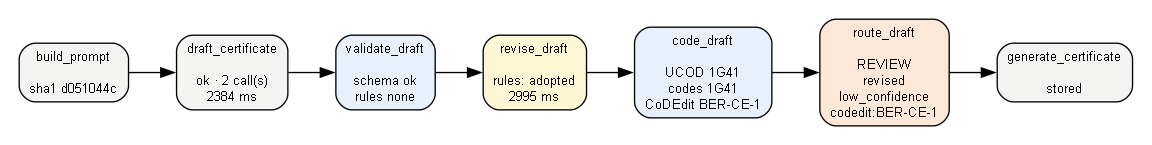

In [25]:
cert = certify_record(record, deps)
print("route:", cert.route.value, "| reasons:", cert.reasons, "| calls:", cert.usage.calls, "| timings:", cert.timings_ms)
print("response keys:", sorted(as_response(cert)))
print("stored only  :", sorted(set(cert.model_dump()) - set(as_response(cert))))
flow_diagram(cert)

In [26]:
render_mccd(cert)

### 4.8 A record the pipeline must not certify

S22 is one of the six held-out scenarios: a death from carbon monoxide in a closed garage, an
external cause with a manner of death to establish, which belongs to the coroner's pathway and not
to this one. The prompt tells the model to decline such records. Expected (live call): `assessment`
is `out_of_scope`, Part I is empty, and the route is `review` with the reason
`assessment:out_of_scope`. If the model certifies it anyway, that is a failure the stress sample in
section 6 counts under `must_not: certify`; on this model it happens on some of the six held-out
cases (a tetanus after a garden injury reads like a disease to it), which is one reason the route is
`review` and never `auto` for a decline.


In [27]:
s22, d22 = scenarios()["S22"], demographics()["S22"]
age, unit = age_from_iso(d22.get("age_iso"))
oos_record = Record(record_id="S22", sex=d22.get("sex"), age=age, age_unit=unit,
                    notes=[{"name": "case_narrative", "text": s22["narrative"]}])
print(s22["narrative"][:400], "...")
oos_cert = certify_record(oos_record, deps)
print()
print("assessment:", (oos_cert.certificate or {}).get("assessment"), "| decline_reason:", (oos_cert.certificate or {}).get("decline_reason"))
print("route     :", oos_cert.route.value, "| reasons:", oos_cert.reasons, "| Part I lines:", len((oos_cert.certificate or {}).get("part1") or []))

On May 5, 2003, a 54-year-old male was found dead from carbon monoxide poisoning in an automobile in a closed garage. A hose, running into the passenger compartment of the car, was attached to the exhaust pipe. The deceased had been despondent for some time as a result of a malignancy, and letters found in the car indicated intent to take his own life. ...



assessment: out_of_scope | decline_reason: forensic_expertise_required
route     : review | reasons: ['assessment:out_of_scope'] | Part I lines: 0


## 5. The routes, and what a reviewer does

Two routes, and a list of reasons that is the reviewer's worklist:

| reason | what the reviewer checks |
|---|---|
| `low_confidence` | the model was not sure; read the note it left and the chain |
| `validator:V1` to `V10` | a rule still fails after revision; the error text names the line |
| `revised`, `terms_revised` | the certificate was changed once; compare with the first draft in the row |
| `schema_invalid`, `model_refused`, `model_truncated`, `model_invalid` | the model did not answer properly; rerun, or certify by hand |
| `part1_line_uncoded`, `autocode_low_score` | a term the WHO coder could not match; reword it |
| `no_ucod` | DORIS could not select an underlying cause; the chain is implausible |
| `codedit:FER-CE-931` | the underlying cause is ill-defined; find the disease behind it |
| `codedit:<other id>` | another WHO quality check; the id is looked up in the CoDEdit documentation |
| `assessment:out_of_scope`, `assessment:insufficient` | the model declined; confirm, or send the record to the right pathway |
| `demographics_missing` | the record had no sex or age; add them and rerun |
| `icd_unavailable`, `icd_error` | the WHO container failed; rerun when it is back |

A certificate routed `auto` has none of these. In a registry system it would be accepted as
written; in this project it is still a proposal, because the client decides what `auto` is allowed
to mean.


## 6. How we measure

You cannot read a hundred certificates and know whether the pipeline is good. The mini harness in
`eval.py` runs it on the 17 teaching scenarios that have answers and reports four numbers: the
share of first drafts that pass the gate, the share after revision, the share routed `auto`, and
the share whose underlying cause code equals the gold's. The last one is the honest measure of
whether the model understood the medicine; the first is the honest measure of whether it followed
the rules.

The 34-case stress sample has no gold; it is scored on behaviour. Each case says what the pipeline
is expected to do (certify, decline, either) and what it must never do (certify a forensic death,
quote the wrong patient's page, certify a negated diagnosis). Those `must_not` violations are the
numbers that must be zero before anyone talks about accuracy.

The cell scores S01 alone through the harness so you can see one row. The how-to guide runs the
whole set and draws the charts.


In [28]:
from automccd_lite.eval import run
res = run("headline", only=("S01",), deps=deps, quiet=True)
row = res["rows"][0]
show_json(row, keys=["id", "route", "reasons", "first_pass", "rules_fired", "repaired", "term_repair",
                     "model_chain", "gold_chain", "ucod_code", "gold_ucod_code", "ucod_code_match", "behaviour_ok"])

{
  "id": "S01-clean",
  "route": "review",
  "reasons": [
    "low_confidence"
  ],
  "first_pass": {
    "schema_ok": true,
    "validator_passed": true,
    "rules_fired": []
  },
  "rules_fired": [],
  "repaired": false,
  "term_repair": null,
  "model_chain": [
    "Staphylococcus aureus meningitis",
    "Septic shock"
  ],
  "gold_chain": [
    "Septic shock",
    "Staphylococcus aureus sepsis",
    "Staphylococcus aureus meningitis"
  ],
  "ucod_code": "1G41",
  "gold_ucod_code": "1B54",
  "ucod_code_match": "different",
  "behaviour_ok": true
}


## Where to go from here

- Read `pipeline.py` now. It is twenty lines, and every line should be familiar.
- Change something and watch the numbers: a rule in `validate.py`, the prompt, the model.
- When your own PoC disagrees with this one, run both on S01 and compare stage by stage with the
  functions you used here. The difference will be in one stage, and now you know which function to
  call to find it.
